In [1]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass

In [2]:
@dataclass
class PMT:
    # просто храним координаты и радиус
    pos: np.ndarray
    r: float

In [3]:
class Detector:
    def __init__(self, R, N, r, a):
        self.R = R
        self.N = N
        self.r = r
        self.a = a
        self.pmts = []
        self._make_pmts()
    
    def _make_pmts(self):
        i = np.arange(self.N) + 0.5
        phi = np.arccos(1 - 2*i/self.N)
        theta = np.pi * (1 + 5**0.5) * i
        x = self.R * np.sin(phi) * np.cos(theta)
        y = self.R * np.sin(phi) * np.sin(theta)
        z = self.R * np.cos(phi)
        
        for k in range(self.N):
            self.pmts.append(PMT(np.array([x[k], y[k], z[k]]), self.r))
    
    def is_on_pmt(self, point):
        for p in self.pmts:
            if np.linalg.norm(point - p.pos) <= p.r:
                return True
        return False
    
    def which_pmt(self, point):
        for i, p in enumerate(self.pmts):
            if np.linalg.norm(point - p.pos) <= p.r:
                return i
        return -1

In [4]:
det = Detector(R=2.0, N=40, r=0.1, a=0.5)

print(f"Создан детектор: R={det.R} м, N={det.N}, r={det.r*100:.0f} см, a={det.a}")
print(f"Первые три ФЭУ:")
for p in det.pmts[:3]:
    print(f"  {p.pos}")

Создан детектор: R=2.0 м, N=40, r=10 см, a=0.5
Первые три ФЭУ:
  [ 0.16104292 -0.41420427  1.95      ]
  [-0.68149594  0.33624883  1.85      ]
  [0.92965601 0.27062835 1.75      ]


In [5]:
# проверка на нескольких точках

p1 = det.pmts[0].pos
print("точка в центре ФЭУ 0:", det.is_on_pmt(p1))

offset = np.array([0.05, 0.0, 0.0])
p2 = p1 + offset
p2 = p2 / np.linalg.norm(p2) * det.R
print("точка рядом с ФЭУ 0:", det.is_on_pmt(p2))

mid = (det.pmts[0].pos + det.pmts[1].pos) / 2
mid = mid / np.linalg.norm(mid) * det.R
print("точка между ФЭУ 0 и 1:", det.is_on_pmt(mid))

rnd = np.random.randn(3)
rnd = rnd / np.linalg.norm(rnd) * det.R
print("случайная точка:", det.is_on_pmt(rnd))

точка в центре ФЭУ 0: True
точка рядом с ФЭУ 0: True
точка между ФЭУ 0 и 1: False
случайная точка: False


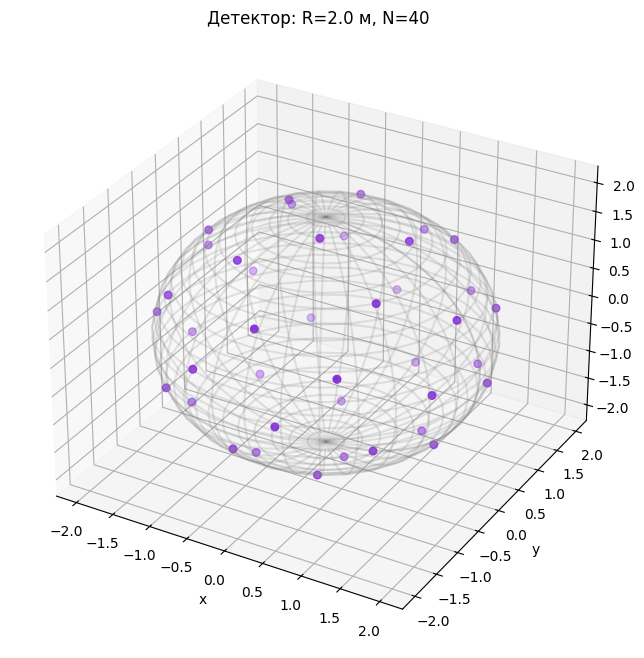

In [6]:
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

# рисуем сферу каркасом
u = np.linspace(0, 2*np.pi, 30)
v = np.linspace(0, np.pi, 30)
xs = det.R * np.outer(np.cos(u), np.sin(v))
ys = det.R * np.outer(np.sin(u), np.sin(v))
zs = det.R * np.outer(np.ones_like(u), np.cos(v))
ax.plot_wireframe(xs, ys, zs, color='gray', alpha=0.2)

# точки ФЭУ
pts = np.array([p.pos for p in det.pmts])
ax.scatter(pts[:,0], pts[:,1], pts[:,2], c='blueviolet', s=30)

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_title(f'Детектор: R={det.R} м, N={det.N}')
plt.show()

In [7]:
import k3d

def make_sphere_mesh(R, n_u=40, n_v=20):
    u = np.linspace(0, 2*np.pi, n_u, endpoint=False)
    v = np.linspace(0, np.pi, n_v)
    uu, vv = np.meshgrid(u, v, indexing='ij')
    x = R * np.sin(vv) * np.cos(uu)
    y = R * np.sin(vv) * np.sin(uu)
    z = R * np.cos(vv)
    
    vertices = np.stack([x, y, z], axis=-1).reshape(-1, 3).astype(np.float32)
    
    indices = []
    for i in range(n_u):
        for j in range(n_v - 1):
            i0 = i * n_v + j
            i1 = ((i + 1) % n_u) * n_v + j
            i2 = ((i + 1) % n_u) * n_v + (j + 1)
            i3 = i * n_v + (j + 1)
            indices += [[i0, i1, i2], [i0, i2, i3]]
    indices = np.array(indices, dtype=np.uint32)
    
    return vertices, indices


verts, idxs = make_sphere_mesh(det.R)
plot = k3d.plot(grid_visible=False)
plot += k3d.mesh(verts, idxs, color=0x888888, opacity=0.15,
                 wireframe=False, side='double')
pts = np.array([p.pos for p in det.pmts]).astype(np.float32)
plot += k3d.points(pts, point_size=0.08, color=0x8A2BE2, shader='3d')
plot.display()

Output()